## Homework on Bass Model: Diffusion of Apple AirPods Pro 3
**Course:** DS223: Marketing Analytics  | **Date:** October 19th, 2026  |  **Student:** Robert Shakhnazarian

**Approach in one paragraph.** Forecast the diffusion of *AirPods Pro 3* by (1) picking a look-alike innovation from the past (*Google Translate*), (2) estimating Bass parameters `p` (innovation) and `q` (imitation) from a time series for the look-alike, (3) choosing a scope and sizing the market potential `M` for the new product with a Fermi estimate, and (4) projecting adopters per period with the Bass model.

## 1. The chosen innovation: Apple AirPods Pro 3

* **TIME Best Inventions 2025 entry:** <https://time.com/collections/best-inventions-2025/7318483/apple-airpods-pro-3/>
* **TIME description:** AirPods Pro 3 deliver advanced noise cancellation, heart rate tracking, hearing assistance, and real-time language translation directly in your ears.

Facts from Apple's launch announcement (Apple, 2025):

| Item | Fact |
|---|---|
| Launch | Pre-orders 9 Sep 2025, availability **19 Sep 2025** |
| US price | from **\$249** |
| Availability at launch | US and 50+ other countries/regions |
| Live Translation requires | an Apple Intelligence-enabled iPhone running iOS 26+ (also works on AirPods Pro 2 and AirPods 4 with ANC) |
| Other headline features | optical heart-rate sensor; hearing-aid feature (Conversation Boost) |

Source: Apple Newsroom, *Introducing AirPods Pro 3* (Sep 2025), <https://www.apple.com/newsroom/2025/09/introducing-airpods-pro-3-the-ultimate-audio-experience/>.

## 2. The look-alike innovation: Google Translate

Both Google Translate and Apple AirPods Pro 3 aim to overcome language barriers by using artificial intelligence to translate conversations between people speaking different languages. However, Google Translate originally relied on smartphones and their screens or speakers to deliver translations, whereas AirPods Pro 3 integrate Live Translation directly into wireless earbuds, allowing users to communicate more naturally without constantly looking at a screen. Both innovations demonstrate how advances in AI and speech recognition have made communication across languages more accessible. While Google Translate helped popularize instant digital translation, AirPods Pro 3 represent a further step toward making this technology seamless, hands-free, and integrated into everyday life.

**Market impact and a caveat on comparability.** Google Translate reached more than 500 million users and supported 103 languages by its tenth anniversary in 2016 (Google, 2016), which shows how quickly a convenience-driven language technology can spread once it is on a device people already carry. The key difference is cost and distribution: Google Translate is a free service, so adoption is limited mainly by awareness and word of mouth, while AirPods Pro 3 is a \$249 piece of hardware tied to the Apple ecosystem and to Apple Intelligence-capable iPhones. The look-alike's `p` and `q` therefore may not transfer well to the earbuds, which is why Section 7 also shows a benchmark case that uses textbook values.

Sources: Google, *Ten years of Google Translate* (28 Apr 2016), <https://blog.google/products/translate/ten-years-of-google-translate/>.

## 3. Historical data for the look-alike

Statista only offered cross-sectional/panel data for this product, so I used **Google Trends** worldwide search interest for the term "Google Translate", 2004 to present, as a proxy for adoption activity.

* Source: Google Trends, search term "Google Translate", Worldwide, 2004-present, <https://trends.google.com/trends/explore?date=all&q=Google%20Translate>
* Export the chart as CSV and save it as `data/google_translate_trends.csv`.

**Note about this proxy.** Google Trends is an index from 0 to 100 (100 = the peak month), not a count of users. So:
* `p` and `q` are *rates per year* and do not depend on the scale of the index, so they can be transferred to the new product.
* The estimated `M` for this series is in *index units* and has no meaning in users. We therefore size `M` for AirPods Pro 3 separately in Section 6.
* Search interest is a flow of attention. We treat it as proportional to the flow of new adopters, which is an assumption.

In [18]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

import helper_functions as hf

Path("img").mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

LAUNCH_YEAR = 2006      # Google Translate launched in April 2006 (Google, 2016: "ten years" in April 2016)
LAST_FULL_YEAR = 2025   # 2026 is incomplete at the time of writing (Oct 2026)

raw = hf.load_trends("data/google_translate_trends.csv")
print(raw.shape, raw.date.min().date(), "to", raw.date.max().date())
raw.head()

(274, 2) 2004-01-01 to 2026-10-01


,date,interest
0,2004-01-01,0.5
1,2004-02-01,0.5
2,2004-03-01,0.5
3,2004-04-01,0.5
4,2004-05-01,0.5


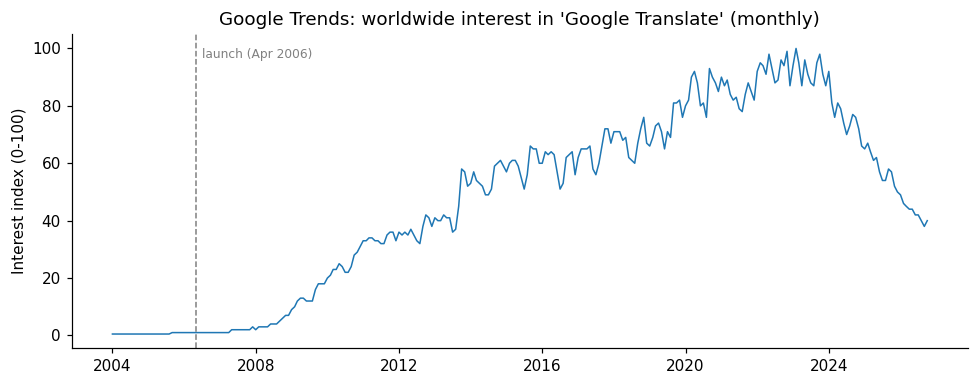

In [19]:
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.plot(raw.date, raw.interest, lw=1)
ax.axvline(pd.Timestamp(f"{LAUNCH_YEAR}-04-28"), color="grey", ls="--", lw=1)
ax.text(pd.Timestamp(f"{LAUNCH_YEAR}-07-01"), ax.get_ylim()[1] * 0.92, "launch (Apr 2006)", fontsize=8, color="grey")
ax.set(title="Google Trends: worldwide interest in 'Google Translate' (monthly)", ylabel="Interest index (0-100)")
fig.tight_layout(); fig.savefig("img/trends_monthly.png"); plt.show()

Before the launch (2004 to Apr 2006) the term has no product to search for, so we start the series in the launch year. We use calendar-year averages to remove the strong school-year seasonality, and drop 2026 because it is incomplete.

 year  interest  t
 2006  1.000000  1
 2007  1.750000  2
 2008  4.250000  3
 2009 13.583333  4
 2010 24.333333  5
 2011 33.666667  6
 2012 36.500000  7
 2013 44.166667  8
 2014 54.750000  9
 2015 59.666667 10
 2016 60.000000 11
 2017 64.500000 12
 2018 67.916667 13
 2019 73.166667 14
 2020 85.416667 15
 2021 84.250000 16
 2022 93.000000 17
 2023 92.416667 18
 2024 76.416667 19
 2025 58.416667 20


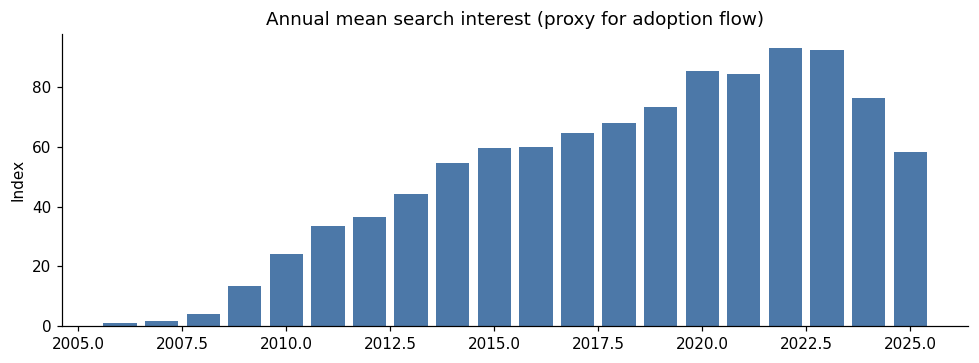

In [20]:
annual = hf.annualise(raw, LAUNCH_YEAR, LAST_FULL_YEAR)
annual.to_csv("data/google_translate_annual.csv", index=False)
print(annual.to_string(index=False))

fig, ax = plt.subplots(figsize=(9, 3.4))
ax.bar(annual.year, annual.interest, color="#4C78A8")
ax.set(title="Annual mean search interest (proxy for adoption flow)", ylabel="Index")
fig.tight_layout(); fig.savefig("img/trends_annual.png"); plt.show()

## 4. Estimating the Bass parameters (p, q, M)

The Bass (1969) model says that the hazard of adopting at time *t* is $p + q\,F(t)$, where $p$ is the coefficient of innovation (independent of others) and $q$ is the coefficient of imitation (word of mouth). The cumulative adoption fraction is

$$F(t)=\frac{1-e^{-(p+q)t}}{1+\frac{q}{p}e^{-(p+q)t}},\qquad \text{adopters in year } t = M\,[F(t)-F(t-1)].$$

We fit by **nonlinear least squares** (many random starts, best SSE kept), and compare with the original **OLS regression** of Bass (1969),

$$S_t = a + b\,N_{t-1} + c\,N_{t-1}^2,$$

where $S_t$ is adoption in period $t$ and $N_{t-1}$ is cumulative adoption up to the previous period. The Bass parameters are recovered from the regression coefficients as

$$M=\frac{-b-\sqrt{b^2-4ac}}{2c},\qquad p=\frac{a}{M},\qquad q=-M\,c.$$

Uncertainty is shown with a residual bootstrap.

In [21]:
t, y = annual.t.values, annual.interest.values

nls = hf.fit_bass_nls(t, y)
ols = hf.fit_bass_ols(y)
t_star, peak = hf.bass_peak(nls["p"], nls["q"], nls["M"])

res = pd.DataFrame({
    "p (per year)": [nls["p"], ols["p"]],
    "q (per year)": [nls["q"], ols["q"]],
    "M (index units)": [nls["M"], ols["M"]],
}, index=["NLS (primary)", "OLS (Bass 1969)"])
display(res.round(4))
print(f"NLS R^2 = {nls['r2']:.3f}   |   implied peak at t* = {t_star:.1f} years after launch "
      f"(~{LAUNCH_YEAR - 1 + t_star:.0f}),  q/p = {nls['q']/nls['p']:.1f}")
if ols["p"] is None:
    print("OLS: no valid root (a>0, c<0, discriminant>=0 not satisfied), so NLS is used.")

,p (per year),q (per year),M (index units)
NLS (primary),0.0057,0.2340,1403.8771
OLS (Bass 1969),0.0091,0.2473,1313.4996


NLS R^2 = 0.945   |   implied peak at t* = 15.5 years after launch (~2020),  q/p = 40.7


,5%,median,95%
p,0.0044,0.0056,0.0069
q,0.2071,0.2352,0.2657
M,1268.3479,1383.7043,1517.9580


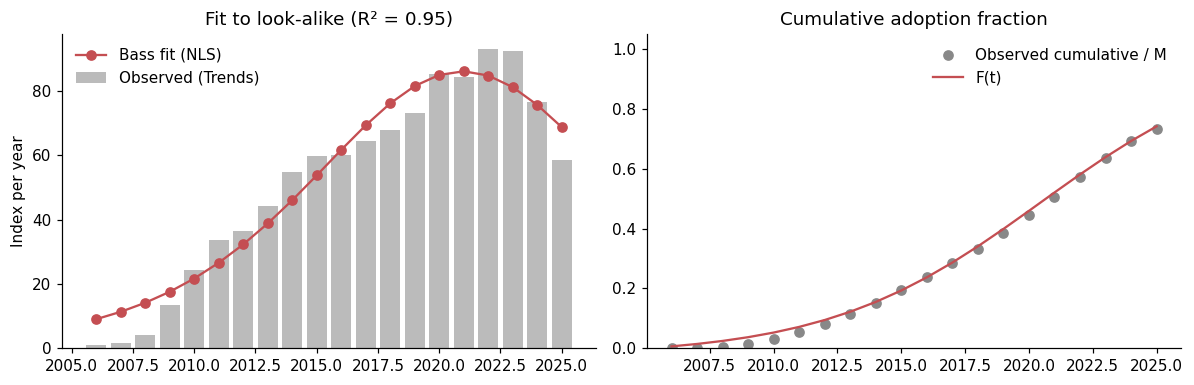

In [22]:
boot = hf.bootstrap_bass(t, y, nls, n_boot=300)
ci = boot.quantile([0.05, 0.5, 0.95]).T
ci.columns = ["5%", "median", "95%"]
display(ci.round(4))

# fit plot
tt = np.arange(0, len(t) + 1)
fit_flow = hf.bass_flow(tt, nls["p"], nls["q"], nls["M"])
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].bar(annual.year, y, color="#BBBBBB", label="Observed (Trends)")
ax[0].plot(annual.year, fit_flow, "o-", color="#C44E52", label="Bass fit (NLS)")
ax[0].set(title=f"Fit to look-alike (R² = {nls['r2']:.2f})", ylabel="Index per year"); ax[0].legend(frameon=False)
ax[1].plot(annual.year, np.cumsum(y) / nls["M"], "o", color="#888", label="Observed cumulative / M")
ax[1].plot(annual.year, hf.bass_cdf(t, nls["p"], nls["q"]), color="#C44E52", label="F(t)")
ax[1].set(title="Cumulative adoption fraction", ylim=(0, 1.05)); ax[1].legend(frameon=False)
fig.tight_layout(); fig.savefig("img/bass_fit_google_translate.png"); plt.show()

**Benchmark check.** In the meta-analysis of Sultan, Farley and Lehmann (1990) the average Bass coefficients across many products were about `p ≈ 0.03` and `q ≈ 0.38`. We compare our estimates with them below. Estimates far outside this range deserve a second look, but a *free software service* is not a typical consumer durable, so some difference is expected.

In [23]:
bench = pd.DataFrame({"p": [0.03, nls["p"]], "q": [0.38, nls["q"]]},
                     index=["Sultan, Farley & Lehmann (1990) mean", "Google Translate (this fit)"])
display(bench.round(3))

,p,q
"Sultan, Farley & Lehmann (1990) mean",0.030,0.380
Google Translate (this fit),0.006,0.234


### Robustness: monthly data

As a check, we refit on the monthly series (time in years, flow per month). Monthly data contain seasonality, so we expect a lower R² but similar `p` and `q`.

In [24]:
m = raw[(raw.date.dt.year >= LAUNCH_YEAR) & (raw.date.dt.year <= LAST_FULL_YEAR)].copy()
m["t"] = (m.date.dt.year - LAUNCH_YEAR) * 12 + m.date.dt.month   # month index 1..N
ymo = m.interest.values
def monthly_model(tm, p, q, M):
    tm = np.asarray(tm, float) / 12   # months -> years
    return M * (hf.bass_cdf(tm, p, q) - hf.bass_cdf(tm - 1 / 12, p, q))
from scipy.optimize import curve_fit
tot = ymo.sum()
best = None
rng = np.random.default_rng(0)
for _ in range(40):
    p0, q0 = 10 ** rng.uniform(-4, -0.7), 10 ** rng.uniform(-2, 0.5)
    try:
        popt, _ = curve_fit(monthly_model, m.t.values, ymo, p0=[p0, q0, tot * rng.uniform(1, 5)],
                            bounds=([1e-5, 1e-3, tot * 0.8], [1, 5, tot * 100]), maxfev=20000)
    except Exception:
        continue
    sse = np.sum((ymo - monthly_model(m.t.values, *popt)) ** 2)
    if best is None or sse < best[0]:
        best = (sse, popt)
if best is None:
    print("Monthly NLS did not converge.")
else:
    pm, qm, Mm = best[1]
    r2m = 1 - best[0] / np.sum((ymo - ymo.mean()) ** 2)
    print(f"Monthly fit: p = {pm:.4f}, q = {qm:.4f}, R² = {r2m:.3f}   (annual fit: p = {nls['p']:.4f}, q = {nls['q']:.4f})")

Monthly fit: p = 0.0057, q = 0.2344, R² = 0.930   (annual fit: p = 0.0057, q = 0.2340)


## 5. Choosing the scope: global

**Decision: global.** Reasons:

1. **The look-alike data are global.** The Google Trends series is worldwide, so `p` and `q` describe global diffusion. Applying them to a single country would mix scopes.
2. **The product is launched globally.** AirPods Pro 3 went on sale in the US and 50+ other countries at once (Apple, 2025), and Apple reports its installed base globally (2.35 billion active devices, Apple Q1 FY2025 results, as reported by iDropNews, 2025).
3. **No usable country-level data.** Apple does not publish AirPods units by country, so a country-specific `M` would rest on even weaker assumptions.

A country-level version (for example Armenia) could be done by replacing the iPhone base in Section 6 with a local figure, but we do not have a credible reference for that, so we keep the global scope.

## 6. Market potential M for AirPods Pro 3 (Fermi estimate)

Apple does not disclose AirPods unit sales, so we build `M` from the bottom up. Logic: someone can only use the headline feature (Live Translation) if they own an Apple Intelligence-capable iPhone, and only a part of them will buy AirPods Pro 3.

$$M = N_{\text{iPhone}} \times s_{\text{AI}} \times s_{\text{buy}}$$

| Symbol | Meaning | Low | Base | High | Basis |
|---|---|---|---|---|---|
| N_iPhone | active iPhones worldwide | 1.0 bn | 1.3 bn | 1.46 bn | Analysts say "over one billion" (iDropNews, 2025); DemandSage puts it at 1.46 bn (cited in Intego, 2024) |
| s_AI | share that is Apple Intelligence-capable over the forecast horizon | 15% | 25% | 40% | **Assumption.** Only ~7% in mid-2024 (iPhone 15 Pro/Pro Max, Intego 2024); rises as newer models replace old ones |
| s_buy | share of those users who ever buy AirPods Pro 3 | 15% | 25% | 35% | **Assumption.** Not sourced; checked against Apple's AirPods volume below |

**Sanity check.** Apple shipped about 81.8 million smart personal audio devices in 2024, an 18% global share (Canalys, as reported by Apple World Today, 2025). That figure covers all of Apple's audio products, so AirPods Pro 3 is only a part of it. The base `M` should therefore imply annual adopters well below that number.

> The three rows marked *Assumption* are the weak points of the analysis. They are Fermi assumptions as the task allows, but they should be replaced by a cited number if one becomes available.

In [25]:
scen = pd.DataFrame({
    "N_iPhone": [1.00e9, 1.30e9, 1.46e9],
    "s_AI":     [0.15,   0.25,   0.40],
    "s_buy":    [0.15,   0.25,   0.35],
}, index=["Low", "Base", "High"])
scen["M"] = scen.N_iPhone * scen.s_AI * scen.s_buy
display((scen.assign(M_millions=scen.M / 1e6)[["N_iPhone", "s_AI", "s_buy", "M_millions"]]).round(3))
APPLE_AUDIO_2024 = 81.8e6   # Canalys via Apple World Today (2025); all Apple audio, not only AirPods Pro 3

,N_iPhone,s_AI,s_buy,M_millions
Low,1.000000e+09,0.15,0.15,22.50
Base,1.300000e+09,0.25,0.25,81.25
High,1.460000e+09,0.40,0.35,204.40


## 7. Predicting the diffusion of AirPods Pro 3 and adopters by period

We take `p` and `q` from the look-alike fit (Section 4) and `M` from the Fermi estimate (Section 6). Time zero is the launch on **19 Sep 2025**, so *Year 1* is roughly Sep 2025 to Sep 2026.

We show three cases:
* **Base:** `p`, `q` from the fit, base `M`.
* **Low / High:** same `p`, `q`, with the low / high `M`.
* **Benchmark case:** base `M` but `p` and `q` set to the Sultan-Farley-Lehmann averages (0.03 and 0.38), as a hedge because the look-alike is a free app and the product is hardware, so its fitted `p`, `q` may not transfer.

In [26]:
p, q = nls["p"], nls["q"]
M_base = scen.loc["Base", "M"]
N_YEARS = 10

yearly = hf.adopters_table(p, q, M_base, N_YEARS, per_year=1)
yearly.insert(1, "window", [f"Sep {2025 + i} - Sep {2026 + i}" for i in range(N_YEARS)])
yearly["adopters_millions"] = yearly.adopters / 1e6
yearly["cumulative_millions"] = yearly.cumulative / 1e6
out = yearly[["period", "window", "adopters_millions", "cumulative_millions", "penetration_pct"]]
out.columns = ["Year since launch", "Window", "New adopters (M)", "Cumulative (M)", "% of market potential"]
display(out.round(2).style.hide(axis="index"))
out.to_csv("data/airpods_pro3_adopters_yearly_base.csv", index=False)

quarterly = hf.adopters_table(p, q, M_base, 5, per_year=4)
quarterly["adopters_millions"] = quarterly.adopters / 1e6
quarterly["cumulative_millions"] = quarterly.cumulative / 1e6
display(quarterly[["period", "adopters_millions", "cumulative_millions", "penetration_pct"]].round(2)
        .rename(columns={"period": "Quarter since launch", "adopters_millions": "New adopters (M)",
                         "cumulative_millions": "Cumulative (M)", "penetration_pct": "% of M"}).style.hide(axis="index"))
quarterly.to_csv("data/airpods_pro3_adopters_quarterly_base.csv", index=False)

t_star, peak = hf.bass_peak(p, q, M_base)
print(f"Base case: peak adoption {t_star:.1f} years after launch (~{2025.72 + t_star:.1f}), "
      f"about {peak/1e6:.1f} M new adopters per year at the peak.")
print(f"Sanity check: peak {peak/1e6:.1f} M per year equals {100*peak/APPLE_AUDIO_2024:.0f}% of Apple's total 2024 audio shipments "
      f"({APPLE_AUDIO_2024/1e6:.1f} M).")

Year since launch,Window,New adopters (M),Cumulative (M),% of market potential
1,Sep 2025 - Sep 2026,0.520000,0.520000,0.650000
2,Sep 2026 - Sep 2027,0.660000,1.180000,1.450000
3,Sep 2027 - Sep 2028,0.820000,2.000000,2.460000
4,Sep 2028 - Sep 2029,1.020000,3.020000,3.710000
5,Sep 2029 - Sep 2030,1.260000,4.270000,5.260000
6,Sep 2030 - Sep 2031,1.540000,5.810000,7.150000
7,Sep 2031 - Sep 2032,1.870000,7.680000,9.450000
8,Sep 2032 - Sep 2033,2.250000,9.930000,12.220000
9,Sep 2033 - Sep 2034,2.660000,12.590000,15.500000
10,Sep 2034 - Sep 2035,3.110000,15.700000,19.330000


Quarter since launch,New adopters (M),Cumulative (M),% of M
1,0.120000,0.120000,0.150000
2,0.130000,0.250000,0.300000
3,0.130000,0.380000,0.470000
4,0.140000,0.520000,0.650000
5,0.150000,0.670000,0.830000
6,0.160000,0.830000,1.030000
7,0.170000,1.000000,1.230000
8,0.180000,1.180000,1.450000
9,0.190000,1.370000,1.690000
10,0.200000,1.570000,1.930000


Base case: peak adoption 15.5 years after launch (~2041.2), about 5.0 M new adopters per year at the peak.
Sanity check: peak 5.0 M per year equals 6% of Apple's total 2024 audio shipments (81.8 M).


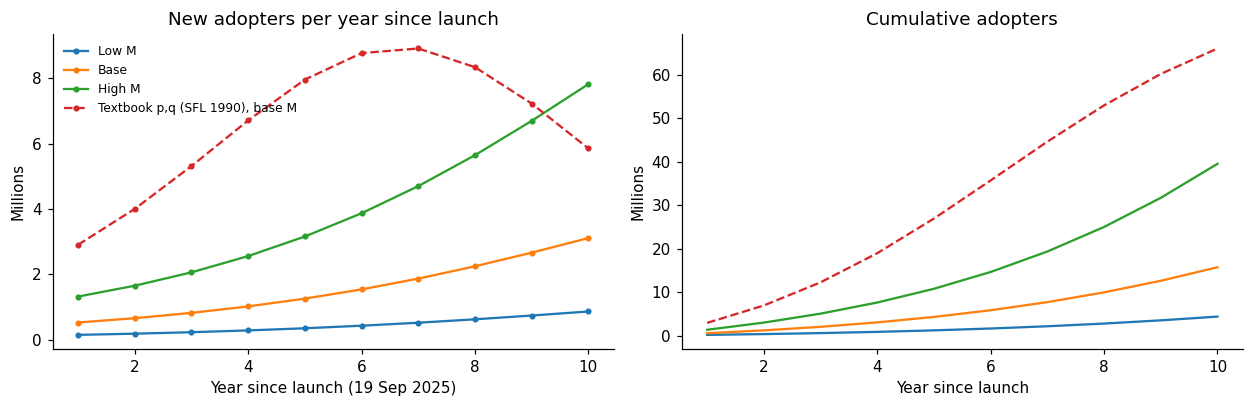

,Year 1 (M),Year 3 (M),Peak year,Peak (M/yr),Cum. 5 yrs (M),Cum. 10 yrs (M)
Low M,0.1,0.2,10.0,0.9,1.2,4.3
Base,0.5,0.8,10.0,3.1,4.3,15.7
High M,1.3,2.1,10.0,7.8,10.7,39.5
"Textbook p,q (SFL 1990), base M",2.9,5.3,7.0,8.9,26.9,66.0


In [27]:
edges = np.arange(0, N_YEARS + 1)
years_x = np.arange(1, N_YEARS + 1)
cases = {
    "Low M":  hf.bass_flow(edges, p, q, scen.loc["Low", "M"]) / 1e6,
    "Base":   hf.bass_flow(edges, p, q, M_base) / 1e6,
    "High M": hf.bass_flow(edges, p, q, scen.loc["High", "M"]) / 1e6,
    "Textbook p,q (SFL 1990), base M": hf.bass_flow(edges, 0.03, 0.38, M_base) / 1e6,
}
fig, ax = plt.subplots(1, 2, figsize=(11.5, 3.8))
for k, v in cases.items():
    ax[0].plot(years_x, v, "o-", ms=3, label=k, ls="--" if "Textbook" in k else "-")
    ax[1].plot(years_x, np.cumsum(v), label=k, ls="--" if "Textbook" in k else "-")
ax[0].set(title="New adopters per year since launch", xlabel="Year since launch (19 Sep 2025)", ylabel="Millions")
ax[1].set(title="Cumulative adopters", xlabel="Year since launch", ylabel="Millions")
ax[0].legend(frameon=False, fontsize=8)
fig.tight_layout(); fig.savefig("img/airpods_pro3_forecast.png"); plt.show()

summary = pd.DataFrame({k: {"Year 1 (M)": v[0], "Year 3 (M)": v[2], "Peak year": int(np.argmax(v)) + 1,
                            "Peak (M/yr)": v.max(), "Cum. 5 yrs (M)": v[:5].sum(), "Cum. 10 yrs (M)": v.sum()}
                        for k, v in cases.items()}).T
display(summary.round(1))
summary.to_csv("data/scenario_summary.csv")

## References

* Apple (2025). *Introducing AirPods Pro 3*. Apple Newsroom. <https://www.apple.com/newsroom/2025/09/introducing-airpods-pro-3-the-ultimate-audio-experience/>
* Bass, F. M. (1969). A new product growth for model consumer durables. *Management Science, 15*(5), 215-227.
* Canalys (2025), reported in: Apple World Today (Mar 2025). *Apple still dominates the global smart personal audio device market with 18% global market share*. <https://appleworld.today/2025/03/apple-still-dominates-the-global-smart-personal-audio-device-market-with-18-global-market-share/>
* Google (2016). *Ten years of Google Translate*. <https://blog.google/products/translate/ten-years-of-google-translate/>
* Google Trends. Search term "Google Translate", Worldwide, 2004-present. <https://trends.google.com/trends/explore?date=all&q=Google%20Translate>
* iDropNews (2025). *Apple reports over 2.35 billion active devices*. <https://www.idropnews.com/news/apple-reports-over-235-billion-active-devices-heres-what-that-means/238755>
* Intego Mac Security Blog (McElhearn, K., 13 Jun 2024). *Apple Intelligence: why most users won't get it*. <https://www.intego.com/mac-security-blog/apple-intelligence-why-most-users-wont-get-it/>
* Sultan, F., Farley, J. U., & Lehmann, D. R. (1990). A meta-analysis of applications of diffusion models. *Journal of Marketing Research, 27*(1), 70-77.
* TIME (2025). *Apple AirPods Pro 3*, Best Inventions of 2025. <https://time.com/collections/best-inventions-2025/7318483/apple-airpods-pro-3/>